**Flood Susceptibility Mapping Using RF**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install rasterio

In [ ]:
# Importing required libraries
import os
import numpy as np
import cv2
import pandas as pd
import rasterio as rio
import joblib
import json
from matplotlib import pyplot as plt
import seaborn as sns
import geopandas as gpd
from sklearn.preprocessing import MinMaxScaler ,StandardScaler
from sklearn.model_selection import train_test_split

**Load the Datasets**

In [ ]:
# Define folder structure
base_dir = "/content/drive/MyDrive/Flood_Susceptibility/flood_susceptibility_project"
data_dir = os.path.join(base_dir, "data")

# Create directories if they don't exist
os.makedirs(data_dir, exist_ok=True)

# Function to load data splits from CSV
def load_data_splits():

    # First check if files exist
    required_files = ['X_train.csv', 'X_val.csv', 'X_test.csv',
                     'y_train.csv', 'y_val.csv', 'y_test.csv',
                     'X_train_scaled.csv', 'X_val_scaled.csv', 'X_test_scaled.csv',
                     'features_list.csv', 'scaler.joblib']

    files_exist = all(os.path.exists(os.path.join(data_dir, file)) for file in required_files)

    if not files_exist:
        print("Error: Data splits not found. Please run save_data_splits() first.")
        return None

    # Load the dataframes
    X_train = pd.read_csv(os.path.join(data_dir, 'X_train.csv'))
    X_val = pd.read_csv(os.path.join(data_dir, 'X_val.csv'))
    X_test = pd.read_csv(os.path.join(data_dir, 'X_test.csv'))

    # Load target variables
    y_train = pd.read_csv(os.path.join(data_dir, 'y_train.csv'))['target'].values
    y_val = pd.read_csv(os.path.join(data_dir, 'y_val.csv'))['target'].values
    y_test = pd.read_csv(os.path.join(data_dir, 'y_test.csv'))['target'].values

    # Load scaled data
    X_train_scaled = pd.read_csv(os.path.join(data_dir, 'X_train_scaled.csv'))
    X_val_scaled = pd.read_csv(os.path.join(data_dir, 'X_val_scaled.csv'))
    X_test_scaled = pd.read_csv(os.path.join(data_dir, 'X_test_scaled.csv'))

    # Load features list
    features_list = pd.read_csv(os.path.join(data_dir, 'features_list.csv'))['features'].tolist()

    # Load scaler
    scaler = joblib.load(os.path.join(data_dir, 'scaler.joblib'))

    # Print summary of loaded data
    print(f"Data splits loaded successfully from {data_dir}!")
    print(f"Training set: {X_train.shape[0]} samples")
    print(f"Validation set: {X_val.shape[0]} samples")
    print(f"Test set: {X_test.shape[0]} samples")

    # Return all data as a dictionary
    return {
        'X_train': X_train,
        'X_val': X_val,
        'X_test': X_test,
        'y_train': y_train,
        'y_val': y_val,
        'y_test': y_test,
        'X_train_scaled': X_train_scaled,
        'X_val_scaled': X_val_scaled,
        'X_test_scaled': X_test_scaled,
        'features_list': features_list,
        'scaler': scaler
    }

In [ ]:
# Load saved splits before training any model
data = load_data_splits()

if data is not None:
    # Extract the data components
    X_train = data['X_train']
    X_val = data['X_val']
    X_test = data['X_test']
    y_train = data['y_train']
    y_val = data['y_val']
    y_test = data['y_test']
    X_train_scaled = data['X_train_scaled']
    X_val_scaled = data['X_val_scaled']
    X_test_scaled = data['X_test_scaled']
    features_list = data['features_list']
    scaler = data['scaler']

Data splits loaded successfully from /content/drive/MyDrive/Flood_Susceptibility/flood_susceptibility_project/data!
Training set: 282 samples
Validation set: 95 samples
Test set: 95 samples


**RANDOM FOREST**

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, f1_score, accuracy_score, precision_score, recall_score

# Define the parameter grid to search
param_grid = {
    'n_estimators': [30, 50, 70, 100],      # Number of trees
    'max_depth': [None, 5, 10, 20],         # Maximum depth of trees
    'min_samples_split': [2, 5, 10],        # Minimum samples required to split a node
    'min_samples_leaf': [1, 2, 4],          # Minimum samples required at a leaf node
    'max_features': ['sqrt', 'log2', None]  # Number of features to consider for best split
}

# Define scoring metrics
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score),
    'recall': make_scorer(recall_score),
    'f1': make_scorer(f1_score)
}

# Create a GridSearchCV object
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='f1',  # Primary scoring metric (you can change to 'accuracy' if preferred)
    cv=5,          # 5-fold cross-validation
    n_jobs=-1,     # Use all available cores
    verbose=2      # Show progress
)

# Fit the grid search to the data
grid_search.fit(X_train_scaled, y_train)

# Print the best parameters and best score
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score: {:.4f}".format(grid_search.best_score_))

# Get the best model
best_rf_model = grid_search.best_estimator_

Fitting 5 folds for each of 432 candidates, totalling 2160 fits
Best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 30}
Best cross-validation score: 0.8633



Validation Performance:
              precision    recall  f1-score   support

           0       0.77      0.90      0.83        41
           1       0.91      0.80      0.85        54

    accuracy                           0.84        95
   macro avg       0.84      0.85      0.84        95
weighted avg       0.85      0.84      0.84        95


Test Performance:
              precision    recall  f1-score   support

           0       0.82      0.82      0.82        44
           1       0.84      0.84      0.84        51

    accuracy                           0.83        95
   macro avg       0.83      0.83      0.83        95
weighted avg       0.83      0.83      0.83        95



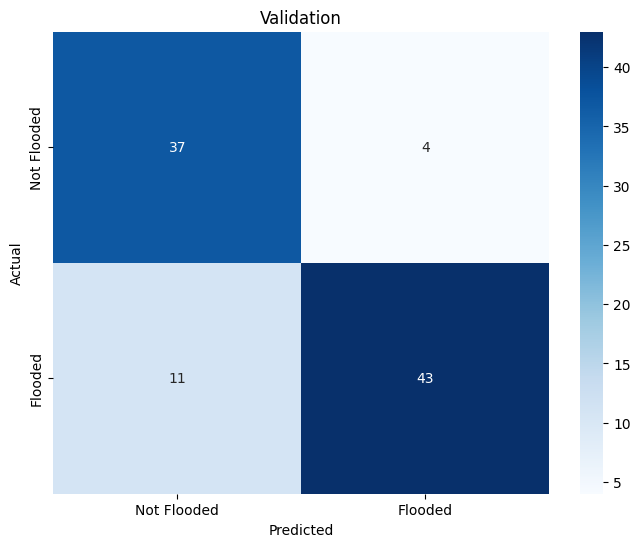

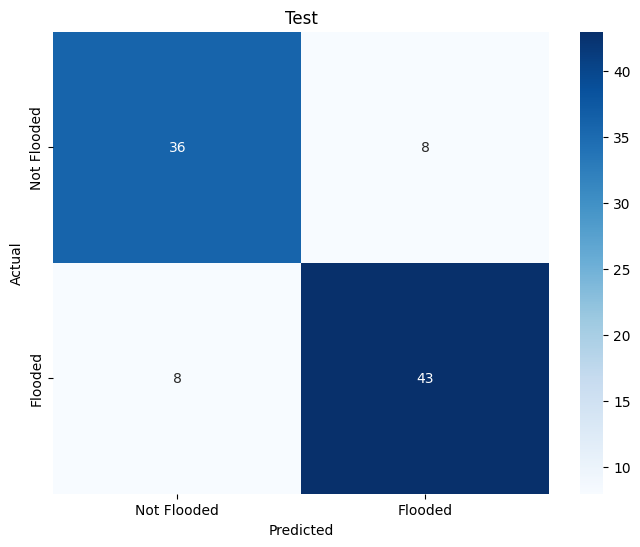

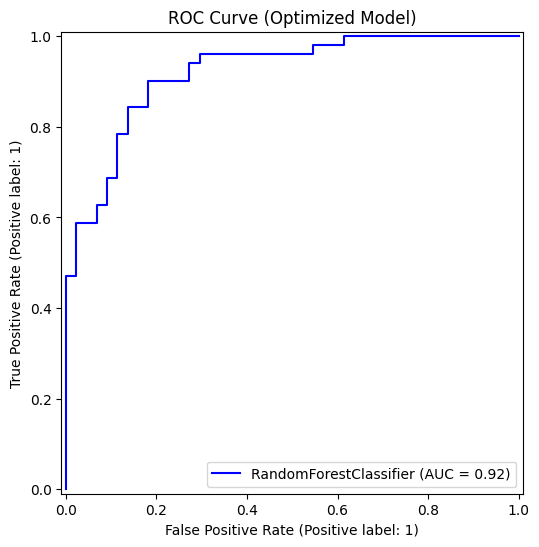

In [ ]:
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report

# Evaluate on validation set
y_val_pred = best_rf_model.predict(X_val_scaled )
print("\nValidation Performance:")
# Print the classification Report
print(classification_report(y_val, y_val_pred))

# Plot confusion matrix
cm = confusion_matrix(y_val, y_val_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Flooded', 'Flooded'], yticklabels=['Not Flooded', 'Flooded'])
plt.title('Validation')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Final evaluation on test set
y_test_pred = best_rf_model.predict(X_test_scaled )
print("\nTest Performance:")
print(classification_report(y_test, y_test_pred))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Flooded', 'Flooded'], yticklabels=['Not Flooded', 'Flooded'])
plt.title('Test')
plt.xlabel('Predicted')
plt.ylabel('Actual')


# Plot ROC curve for the optimized model
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(best_rf_model, X_test_scaled , y_test, ax=ax, color='blue')
plt.title("ROC Curve (Optimized Model)")
plt.show()

In [ ]:
# Define save path
models_dir = "/content/drive/MyDrive/Flood_Susceptibility/flood_susceptibility_project/models"
os.makedirs(models_dir, exist_ok=True)

# Save the model
joblib.dump(best_rf_model, os.path.join(models_dir, 'best_rf_model.pkl'))

['/content/drive/MyDrive/Flood_Susceptibility/flood_susceptibility_project/models/best_rf_model.pkl']

**Prepare Input Data for Prediction**

All predictive rasters must have:
*   The same spatial resolution.
*   The same coordinate reference system (CRS).
*   No missing or NaN values.






In [ ]:
# Read shapefile for the whole study area
df_SA = gpd.read_file("/content/drive/MyDrive/Flood_Susceptibility/Predict_Studyarea/Studyarea_point_filled02.shp")

#Drop the Column 'TPI'
df_SA.drop('TPI', axis=1, inplace=True)
df_SA.head() # make sure that the dataset has the same column arrangement as the training dataset

,Relief,Slope,Dis_River,Drai_Densi,TWI,LULC,Geomorphol,SPI,Conv_Index,Curvature,NDVI,Rainfall,geometry
0,10.0,1.012750,1000.0,0.913382,15.663495,1.0,5.0,5.067031,-33.333332,-0.222222,0.743433,2310.079590,POINT (643740.765 1128139.336)
1,9.0,0.675206,1000.0,0.877988,8.002930,3.0,5.0,2.870944,-58.262466,-0.444444,0.680239,2341.572266,POINT (643740.765 1127139.336)
2,6.0,2.263636,1000.0,0.848125,17.728165,3.0,5.0,7.936322,-19.677816,-0.333333,0.846873,2363.924561,POINT (643740.765 1126639.336)
3,9.0,0.477454,300.0,0.821285,15.102857,1.0,4.0,3.754438,100.000000,-0.000000,0.452289,2374.398682,POINT (643740.765 1126139.336)
4,11.0,2.052775,200.0,0.765568,6.903668,3.0,5.0,3.972924,-5.120819,0.222222,0.323103,2378.946289,POINT (643740.765 1125639.336)


In [ ]:
# we need to remove all the columns except the predictive features
X_SA= df_SA.drop(labels = ["geometry"], axis=1)
X_SA.head()

# Normalize the predictors (X)
X_SA_normalized = pd.DataFrame(scaler.transform(X_SA), columns=X_SA.columns)

# Check the normalized X
X_SA_normalized.head()

prediction_SA = best_rf_model.predict(X_SA_normalized) # predict if the location is flooded (1) or not flooded (0)

# In order to map the flood susceptibility we need to cacluate the probability of being flooded
prediction_prob=best_rf_model.predict_proba(X_SA_normalized) # This function return an array with lists
# each list has two values [probability of being not flooded , probability of being flooded]

# We need only the probablity of being flooded
# We need to add the value coressponding to each point

df_SA['FSM']= prediction_prob[:,1]

print(df_SA.head())

   Relief     Slope  Dis_River  Drai_Densi        TWI  LULC  Geomorphol  \
0    10.0  1.012750     1000.0    0.913382  15.663495   1.0         5.0   
1     9.0  0.675206     1000.0    0.877988   8.002930   3.0         5.0   
2     6.0  2.263636     1000.0    0.848125  17.728165   3.0         5.0   
3     9.0  0.477454      300.0    0.821285  15.102857   1.0         4.0   
4    11.0  2.052775      200.0    0.765568   6.903668   3.0         5.0   

        SPI  Conv_Index  Curvature      NDVI     Rainfall  \
0  5.067031  -33.333332  -0.222222  0.743433  2310.079590   
1  2.870944  -58.262466  -0.444444  0.680239  2341.572266   
2  7.936322  -19.677816  -0.333333  0.846873  2363.924561   
3  3.754438  100.000000  -0.000000  0.452289  2374.398682   
4  3.972924   -5.120819   0.222222  0.323103  2378.946289   

                         geometry       FSM  
0  POINT (643740.765 1128139.336)  0.891667  
1  POINT (643740.765 1127139.336)  0.934127  
2  POINT (643740.765 1126639.336)  0.974444 

In [ ]:
# Select only the geometry and FSM columns
df_SA_simplified = df_SA[["geometry", "FSM"]]

# Save to a new shapefile (or other geospatial format)
df_SA_simplified.to_file("Flood_Susceptibility_Map_RF.shp")

The random forest model has a built-in **feature importance function** which is implemented in scikit-learn python module. Hence, we can estimate which predictive features influence the model prediction.


Feature Importance (Tuned Model):
Relief        0.233238
Geomorphol    0.176587
Slope         0.114629
Rainfall      0.101045
TWI           0.084029
NDVI          0.083341
Drai_Densi    0.059058
SPI           0.040381
Conv_Index    0.036130
Curvature     0.031992
LULC          0.021336
Dis_River     0.018233
dtype: float64


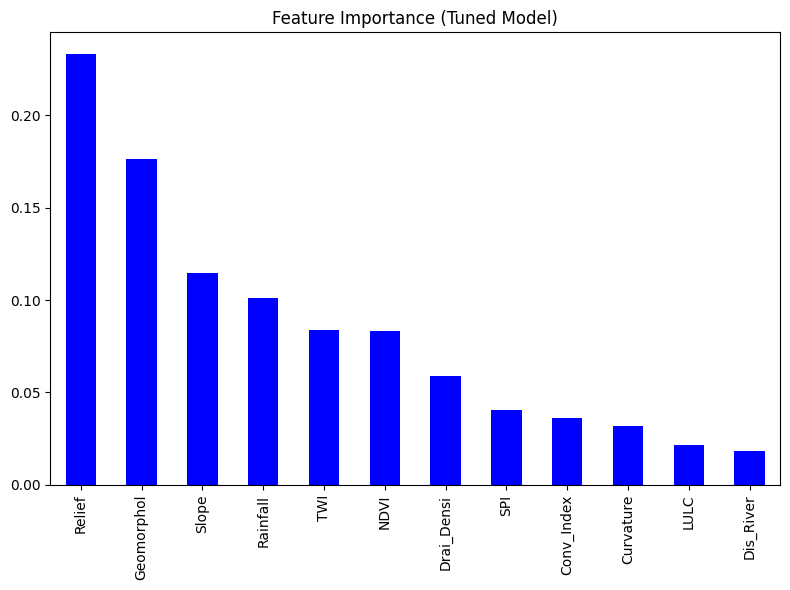

In [ ]:
# Feature importance of the tuned model
tuned_feature_imp = pd.Series(best_rf_model.feature_importances_, index=features_list).sort_values(ascending=False)
print("\nFeature Importance (Tuned Model):")
print(tuned_feature_imp)

# Plot feature importance
plt.figure(figsize=(8, 6))
tuned_feature_imp.plot.bar(color='blue')
plt.title("Feature Importance (Tuned Model)")
plt.tight_layout()
plt.show()

In [ ]:
# Improved rasterization using study area boundary and smoother interpolation
import rasterio
from rasterio import features
from rasterio.mask import mask
from rasterio.transform import from_origin
import numpy as np
from scipy.interpolate import griddata
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import os

def rasterize_points_with_boundary(point_gdf, attribute_column, boundary_shapefile, output_raster, resolution=30, method='linear'):
    """
    Rasterize a point shapefile based on an attribute column at specified resolution,
    constrained to a boundary shapefile and using smooth interpolation.

    Parameters:
    - point_gdf: Point GeoDataFrame with values to be rasterized
    - attribute_column: Column name containing the values to rasterize
    - boundary_shapefile: Path to boundary shapefile to constrain the rasterization
    - output_raster: Path to save the output raster
    - resolution: Pixel resolution in the same units as the shapefile CRS (default: 30m)
    - method: Interpolation method ('linear', 'cubic', or 'nearest')
    """
    print(f"Rasterizing {len(point_gdf)} points with resolution {resolution}m...")

    # Read the boundary shapefile
    boundary_gdf = gpd.read_file(boundary_shapefile)

    # Make sure both datasets have the same CRS
    if point_gdf.crs != boundary_gdf.crs:
        print(f"Reprojecting points to match boundary CRS: {boundary_gdf.crs}")
        point_gdf = point_gdf.to_crs(boundary_gdf.crs)

    # Get the boundary polygon(s)
    boundary_geom = boundary_gdf.geometry.unary_union

    # Get the bounds of the study area
    minx, miny, maxx, maxy = boundary_gdf.total_bounds

    # Extract coordinates and values from points
    x = [geom.x for geom in point_gdf.geometry]
    y = [geom.y for geom in point_gdf.geometry]
    values = point_gdf[attribute_column].values

    # Calculate grid dimensions based on the boundary
    width = int(np.ceil((maxx - minx) / resolution))
    height = int(np.ceil((maxy - miny) / resolution))

    # Create target grid coordinates
    grid_x, grid_y = np.meshgrid(
        np.arange(minx, minx + width * resolution, resolution),
        np.arange(maxy, maxy - height * resolution, -resolution)
    )

    # Create a mask for points inside the boundary
    print("Creating mask for study area boundary...")

    # Create the transformation
    transform = from_origin(minx, maxy, resolution, resolution)

    # Perform the interpolation with the specified method
    print(f"Interpolating values using {method} method...")
    grid_z = griddata((x, y), values, (grid_x, grid_y), method=method)

    # Create the initial raster dataset
    print("Creating initial raster...")
    with rasterio.open(
        'temp_raster.tif',
        'w',
        driver='GTiff',
        height=height,
        width=width,
        count=1,
        dtype=np.float32,
        crs=boundary_gdf.crs,
        transform=transform,
    ) as dst:
        # Fill NoData values with -9999
        grid_z = np.nan_to_num(grid_z, nan=-9999)
        dst.write(grid_z, 1)
        dst.nodata = -9999

    # Clip the raster to the boundary
    print("Clipping raster to study area boundary...")
    with rasterio.open('temp_raster.tif') as src:
        # Get geometry in GeoJSON format for rasterio
        boundary_features = [feature['geometry'] for feature in boundary_gdf.__geo_interface__['features']]

        # Perform the masking operation
        out_image, out_transform = mask(src, boundary_features, crop=True, nodata=-9999)

        # Update metadata
        out_meta = src.meta.copy()
        out_meta.update({
            "height": out_image.shape[1],
            "width": out_image.shape[2],
            "transform": out_transform,
            "nodata": -9999
        })

        # Write the clipped raster
        with rasterio.open(output_raster, "w", **out_meta) as dest:
            dest.write(out_image)

    # Remove temporary file
    if os.path.exists('temp_raster.tif'):
        os.remove('temp_raster.tif')

    print(f"Rasterization complete. Saved to {output_raster}")
    return output_raster

# Define paths and parameters
point_data = df_SA_simplified  # Your existing GeoDataFrame
attribute_column = "FSM"
boundary_shapefile = "/content/drive/MyDrive/Flood_Susceptibility/ALUVA.shp"
output_raster = "Best_RF_Flood_Susceptibility_Map_30m_improved02.tif"
output_image = "Best_Flood_Susceptibility_Map_Visualization_improved.png"


#call the function
rasterize_points_with_boundary(point_data, attribute_column, boundary_shapefile, output_raster)

Rasterizing 2064 points with resolution 30m...
Creating mask for study area boundary...
Interpolating values using linear method...


/tmp/ipykernel_3115/606532773.py:37: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  boundary_geom = boundary_gdf.geometry.unary_union


Creating initial raster...
Clipping raster to study area boundary...
Rasterization complete. Saved to Best_RF_Flood_Susceptibility_Map_30m_improved02.tif


'Best_RF_Flood_Susceptibility_Map_30m_improved02.tif'

Creating map with legend at bottom...
Improved classified map saved to Classified_Map_Bottom_Legend.png


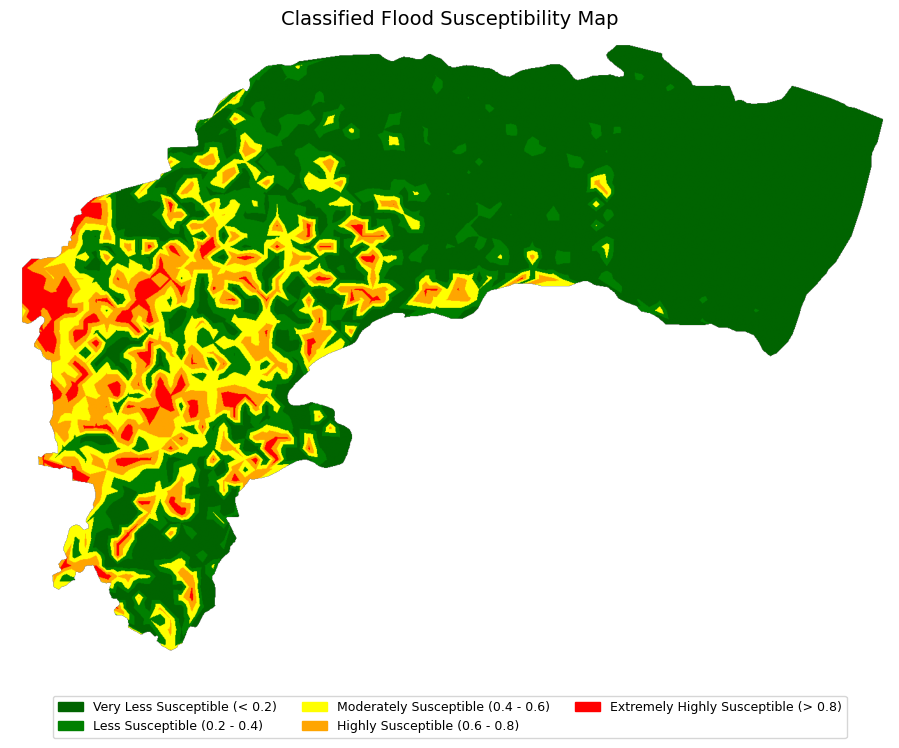

In [ ]:
# Improved visualization of classified flood susceptibility map
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches

def visualize_improved_classified_map(raster_path, output_image=None):
    """
    Create an improved visualization of the classified flood susceptibility map
    with better legend placement and sizing

    Parameters:
    - raster_path: Path to the flood susceptibility raster
    - output_image: Path to save the visualization (optional)
    """
    # Open the raster file
    with rasterio.open(raster_path) as src:
        flood_susceptibility = src.read(1)

        # Replace NoData values with NaN for better visualization
        if src.nodata is not None:
            flood_susceptibility = np.where(flood_susceptibility == src.nodata, np.nan, flood_susceptibility)

        # Create a figure with a reasonable size
        plt.figure(figsize=(10, 8))

        # Define the classes and their boundaries
        bounds = [0, 0.2, 0.4, 0.6, 0.8, 1.0]

        # Define colors for each class
        colors = ['darkgreen', 'green', 'yellow', 'orange', 'red']

        # Create a colormap
        cmap = ListedColormap(colors)

        # Create a norm to map values to colors
        norm = BoundaryNorm(bounds, cmap.N)

        # Plot the classified raster
        im = plt.imshow(flood_susceptibility, cmap=cmap, norm=norm)

        # Create custom legend elements
        legend_elements = [
            mpatches.Patch(color='darkgreen', label='Very Less Susceptible (< 0.2)'),
            mpatches.Patch(color='green', label='Less Susceptible (0.2 - 0.4)'),
            mpatches.Patch(color='yellow', label='Moderately Susceptible (0.4 - 0.6)'),
            mpatches.Patch(color='orange', label='Highly Susceptible (0.6 - 0.8)'),
            mpatches.Patch(color='red', label='Extremely Highly Susceptible (> 0.8)')
        ]

        # Position the legend outside the map area
        plt.legend(handles=legend_elements,
                  loc='upper center',
                  bbox_to_anchor=(0.5, -0.05),  # Position below the map
                  ncol=3,  # Display in 3 columns to save space
                  fontsize=9)

        plt.title('Classified Flood Susceptibility Map', fontsize=14)
        plt.axis('off')

        # Add padding to make room for the legend
        plt.tight_layout()
        plt.subplots_adjust(bottom=0.2)  # Make room for legend at bottom

        # Save if requested
        if output_image:
            plt.savefig(output_image, dpi=300, bbox_inches='tight')
            print(f"Improved classified map saved to {output_image}")

        plt.show()

# Path to your raster file - change this to your actual output path
raster_path = "Best_RF_Flood_Susceptibility_Map_30m_improved02.tif"

# Output paths
map_with_bottom_legend = "Classified_Map_Bottom_Legend.png"
map_with_inset_legend = "Classified_Map_Inset_Legend.png"

# Create both versions so you can choose which works better
print("Creating map with legend at bottom...")
visualize_improved_classified_map(raster_path, map_with_bottom_legend)